# Probability for Machine Learning - Companion Workbook

**Kajola Gbenga**
*Data Scientist & AI Engineer*

This notebook is the executable companion to the *Probability for Machine Learning* module. Every cell below runs using only NumPy, SciPy, Pandas, Matplotlib, and scikit-learn, and produces real, computed output - reproducing and verifying the key derivations, simulations, and worked examples from the module (Bayes' theorem, the distribution catalog, CLT/LLN, Monte Carlo methods, Bayesian updating, Naive Bayes, GMM/EM, Mahalanobis anomaly detection, calibration, numerical stability, and the classic interview-trap problems).

All randomness uses NumPy's modern `default_rng()` generator for full reproducibility, exactly as the module teaches.

In [1]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
pd.set_option('display.max_columns', 50)
print("Environment ready. NumPy, SciPy, Pandas, Matplotlib loaded.")

Environment ready. NumPy, SciPy, Pandas, Matplotlib loaded.


## 1. Basic Probability Rules (Section 8): Verifying Inclusion-Exclusion

In [2]:
n = 1_000_000
large_amount = rng.random(n) < 0.12
new_device = rng.random(n) < 0.08
both = rng.random(n) < 0.025
A = large_amount | both
B = new_device | both

p_union_empirical = (A | B).mean()
p_union_formula = A.mean() + B.mean() - (A & B).mean()
print(f"Empirical P(A union B): {p_union_empirical:.4f}")
print(f"Formula P(A union B):   {p_union_formula:.4f}")

Empirical P(A union B): 0.2104
Formula P(A union B):   0.2104


## 2. Conditional Probability and Bayes' Theorem (Sections 10, 13)

Reproducing the fraud/device-type worked example and the biased-coin Bayes' theorem example.

In [3]:
table = pd.DataFrame({"new_device": [40, 160], "known_device": [20, 780]}, index=["fraud", "not_fraud"])
display(table)
p_fraud_given_new_device = table.loc["fraud", "new_device"] / table["new_device"].sum()
print(f"\nP(Fraud | New Device) = {p_fraud_given_new_device:.2f}")

# Bayes' theorem: the biased-coin example
prior_biased = 0.5
likelihood_H_given_biased = 0.9
likelihood_H_given_fair = 0.5
evidence = likelihood_H_given_biased*prior_biased + likelihood_H_given_fair*(1-prior_biased)
posterior_biased = (likelihood_H_given_biased*prior_biased) / evidence
print(f"P(biased coin | observed Heads) = {posterior_biased:.4f}")


P(Fraud | New Device) = 0.20
P(biased coin | observed Heads) = 0.6429


,new_device,known_device
fraud,40,20
not_fraud,160,780


## 3. The Classic Medical Testing / Base Rate Problem (Sections 98, 116)

Why a 99%-sensitive, 99%-specific test on a rare disease still produces a surprisingly low positive predictive value.

In [4]:
sensitivity, specificity, prevalence = 0.99, 0.99, 0.001

p_positive = sensitivity*prevalence + (1-specificity)*(1-prevalence)
ppv = (sensitivity * prevalence) / p_positive

print(f"P(disease | positive test) = {ppv:.4f}")
print("Even with a 99%/99% test, a positive result on a rare disease is still only ~9% likely to be a true case.")

# Verify via direct simulation
n = 2_000_000
has_disease = rng.random(n) < prevalence
test_positive = np.where(has_disease, rng.random(n) < sensitivity, rng.random(n) < (1-specificity))
ppv_simulated = has_disease[test_positive].mean()
print(f"Simulated PPV: {ppv_simulated:.4f}")

P(disease | positive test) = 0.0902
Even with a 99%/99% test, a positive result on a rare disease is still only ~9% likely to be a true case.
Simulated PPV: 0.0916


## 4. Distribution Catalog: PMF/PDF, Mean, Variance (Section 143)

Every SciPy distribution shares the same `.pmf/.pdf`, `.cdf`, `.ppf`, `.rvs`, `.mean`, `.var` interface.

In [5]:
distributions = {
    "Bernoulli(p=0.02)": stats.bernoulli(p=0.02),
    "Binomial(n=200,p=0.7)": stats.binom(200, 0.7),
    "Poisson(lambda=4)": stats.poisson(mu=4),
    "Geometric(p=0.05)": stats.geom(p=0.05),
    "Exponential(scale=15)": stats.expon(scale=15),
    "Gamma(a=3,scale=2)": stats.gamma(a=3, scale=2),
    "Beta(a=2,b=8)": stats.beta(a=2, b=8),
    "Normal(mu=80,sigma=25)": stats.norm(80, 25),
}
summary = pd.DataFrame({name: {"mean": d.mean(), "variance": d.var()} for name, d in distributions.items()}).T
display(summary.round(3))

,mean,variance
Bernoulli(p=0.02),0.02,0.020
"Binomial(n=200,p=0.7)",140.00,42.000
Poisson(lambda=4),4.00,4.000
Geometric(p=0.05),20.00,380.000
Exponential(scale=15),15.00,225.000
"Gamma(a=3,scale=2)",6.00,12.000
"Beta(a=2,b=8)",0.20,0.015
"Normal(mu=80,sigma=25)",80.00,625.000


## 5. Law of Large Numbers and Central Limit Theorem (Sections 53-54)

Running mean after 10 flips: 0.700
Running mean after 10,000 flips: 0.487
Sample-mean distribution skewness (should be near 0, unlike the original Exponential): 0.319


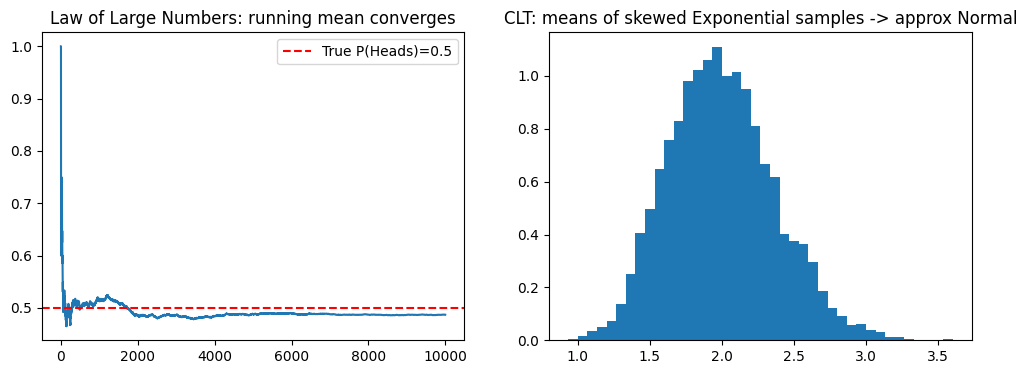

In [6]:
flips = rng.integers(0, 2, size=10000)
running_mean = np.cumsum(flips) / np.arange(1, 10001)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(running_mean)
axes[0].axhline(0.5, color='red', linestyle='--', label='True P(Heads)=0.5')
axes[0].set_title("Law of Large Numbers: running mean converges")
axes[0].legend()

# CLT: sample means of an Exponential (skewed) distribution look Normal
sample_means = [rng.exponential(2, 30).mean() for _ in range(5000)]
axes[1].hist(sample_means, bins=40, density=True)
axes[1].set_title("CLT: means of skewed Exponential samples -> approx Normal")

print(f"Running mean after 10 flips: {running_mean[9]:.3f}")
print(f"Running mean after 10,000 flips: {running_mean[-1]:.3f}")
print(f"Sample-mean distribution skewness (should be near 0, unlike the original Exponential): {stats.skew(sample_means):.3f}")

## 6. Monte Carlo Estimation (Section 56)

In [7]:
n = 1_000_000
x, y = rng.uniform(-1, 1, n), rng.uniform(-1, 1, n)
pi_estimate = 4 * ((x**2 + y**2) <= 1).mean()
print(f"Monte Carlo estimate of pi: {pi_estimate:.5f} (true value: {np.pi:.5f})")

# Monte Carlo business risk simulation
revenue = rng.normal(50000, 8000, 100_000)
costs = rng.normal(45000, 5000, 100_000)
profit = revenue - costs
print(f"\nP(loss this month): {(profit < 0).mean():.4f}")
print(f"Expected profit: ${profit.mean():,.0f}")
print(f"5th percentile: ${np.percentile(profit,5):,.0f}   95th percentile: ${np.percentile(profit,95):,.0f}")

Monte Carlo estimate of pi: 3.14078 (true value: 3.14159)

P(loss this month): 0.2984
Expected profit: $4,994
5th percentile: $-10,501   95th percentile: $20,558


## 7. Bayesian Updating: Beta-Bernoulli Conjugate Prior (Sections 14, 65-66)

Sequential updating of a coin's bias, and a full Bayesian fraud-rate estimation example.

In [8]:
alpha, beta_param = 1, 1   # Beta(1,1) = uniform prior
flips = [1, 1, 0, 1, 1, 1, 0, 1]
for i, flip in enumerate(flips, 1):
    alpha += flip
    beta_param += (1 - flip)
    print(f"After flip {i} ({'H' if flip else 'T'}): posterior mean P(Heads) = {alpha/(alpha+beta_param):.3f}")

After flip 1 (H): posterior mean P(Heads) = 0.667
After flip 2 (H): posterior mean P(Heads) = 0.750
After flip 3 (T): posterior mean P(Heads) = 0.600
After flip 4 (H): posterior mean P(Heads) = 0.667
After flip 5 (H): posterior mean P(Heads) = 0.714
After flip 6 (H): posterior mean P(Heads) = 0.750
After flip 7 (T): posterior mean P(Heads) = 0.667
After flip 8 (H): posterior mean P(Heads) = 0.700


Prior mean: 0.0400
Posterior mean: 0.0567
95% credible interval: (np.float64(0.03962542867923239), np.float64(0.07650252961861295))


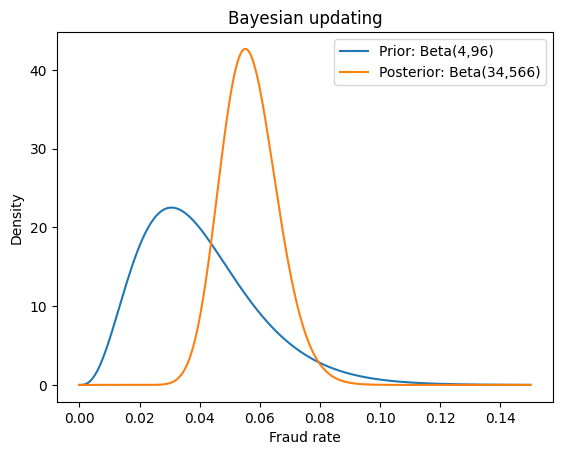

In [9]:
# Full Bayesian fraud-rate estimation, prior -> posterior
prior = stats.beta(4, 96)
successes, n = 30, 500
posterior = stats.beta(4+successes, 96+(n-successes))

x = np.linspace(0, 0.15, 500)
plt.plot(x, prior.pdf(x), label="Prior: Beta(4,96)")
plt.plot(x, posterior.pdf(x), label="Posterior: Beta(34,566)")
plt.legend(); plt.xlabel("Fraud rate"); plt.ylabel("Density"); plt.title("Bayesian updating")

print(f"Prior mean: {prior.mean():.4f}")
print(f"Posterior mean: {posterior.mean():.4f}")
print(f"95% credible interval: {posterior.interval(0.95)}")

## 8. Bayesian A/B Testing (Section 125)

In [10]:
campaign_a = {"visitors": 5000, "conversions": 245}
campaign_b = {"visitors": 5200, "conversions": 287}

posterior_A = stats.beta(1 + campaign_a["conversions"], 1 + campaign_a["visitors"] - campaign_a["conversions"])
posterior_B = stats.beta(1 + campaign_b["conversions"], 1 + campaign_b["visitors"] - campaign_b["conversions"])

samples_A = posterior_A.rvs(100_000, random_state=rng)
samples_B = posterior_B.rvs(100_000, random_state=rng)
p_b_better = (samples_B > samples_A).mean()

print(f"Campaign A posterior mean: {posterior_A.mean():.4f}")
print(f"Campaign B posterior mean: {posterior_B.mean():.4f}")
print(f"P(Campaign B's true rate exceeds Campaign A's) = {p_b_better:.4f}")
print(f"Expected relative lift: {((samples_B - samples_A)/samples_A).mean()*100:.2f}%")

Campaign A posterior mean: 0.0492
Campaign B posterior mean: 0.0554
P(Campaign B's true rate exceeds Campaign A's) = 0.9197
Expected relative lift: 13.01%


## 9. Maximum Likelihood Estimation (Section 62)

In [11]:
data = np.array([12.1, 11.8, 12.4, 12.0, 11.9, 12.3, 12.2])
mu_hat, sigma_hat = data.mean(), data.std(ddof=0)
print(f"Analytical Gaussian MLE: mu={mu_hat:.4f}, sigma={sigma_hat:.4f}")

from scipy.optimize import minimize_scalar
neg_log_likelihood = lambda mu: -stats.norm(loc=mu, scale=sigma_hat).logpdf(data).sum()
result = minimize_scalar(neg_log_likelihood)
print(f"Numerically optimized MLE for mu: {result.x:.4f}  (should match analytical mean)")

Analytical Gaussian MLE: mu=12.1000, sigma=0.2000
Numerically optimized MLE for mu: 12.1000  (should match analytical mean)


## 10. Naive Bayes From Scratch, Verified Against scikit-learn (Section 68)

In [12]:
spam_counts = np.array([8, 10, 12, 9, 15])
not_spam_counts = np.array([1, 0, 2, 1, 3])
class_priors = {"spam": 0.4, "not_spam": 0.6}
likelihoods = {
    "spam": stats.norm(spam_counts.mean(), spam_counts.std()),
    "not_spam": stats.norm(not_spam_counts.mean(), not_spam_counts.std()),
}

def classify(x):
    scores = {c: likelihoods[c].pdf(x) * class_priors[c] for c in class_priors}
    total = sum(scores.values())
    return {c: s/total for c, s in scores.items()}

manual_result = classify(x=9)
print("Manual implementation:", manual_result)

from sklearn.naive_bayes import GaussianNB
X = np.array([[8],[10],[12],[9],[15],[1],[0],[2],[1],[3]])
y = np.array(["spam"]*5 + ["not_spam"]*5)
sk_model = GaussianNB().fit(X, y)
print("scikit-learn GaussianNB:", dict(zip(sk_model.classes_, sk_model.predict_proba([[9]])[0])))

Manual implementation: {'spam': np.float64(0.9999999999958642), 'not_spam': np.float64(4.135757483563318e-12)}
scikit-learn GaussianNB: {np.str_('not_spam'): np.float64(2.7571735156761305e-12), np.str_('spam'): np.float64(0.9999999999972427)}


## 11. Numerical Stability: Log-Sum-Exp and Stable Softmax (Section 115)

In [13]:
def naive_softmax(z):
    exp_z = np.exp(z)
    return exp_z / exp_z.sum()

def stable_softmax(z):
    z = z - np.max(z)
    exp_z = np.exp(z)
    return exp_z / exp_z.sum()

small_logits = np.array([2.0, 1.0, 0.1])
print("Naive vs stable softmax (small inputs, both should agree):")
print(" naive: ", naive_softmax(small_logits))
print(" stable:", stable_softmax(small_logits))

large_logits = np.array([1000, 1001, 999])
print("\nWith large inputs, naive softmax overflows to nan; stable softmax still works:")
with np.errstate(over='ignore', invalid='ignore'):
    print(" naive: ", naive_softmax(large_logits))
print(" stable:", stable_softmax(large_logits))

from scipy.special import logsumexp
print(f"\nscipy.special.logsumexp (production-grade version): {logsumexp(large_logits):.4f}")

Naive vs stable softmax (small inputs, both should agree):
 naive:  [0.65900114 0.24243297 0.09856589]
 stable: [0.65900114 0.24243297 0.09856589]

With large inputs, naive softmax overflows to nan; stable softmax still works:
 naive:  [nan nan nan]
 stable: [0.24472847 0.66524096 0.09003057]

scipy.special.logsumexp (production-grade version): 1001.4076


## 12. EM Algorithm for a Gaussian Mixture, From Scratch (Section 82)

Converged means: [20.18 59.89]  (true means were 20 and 60)
Converged mixing weights: [0.6 0.4]  (true weights were 0.6 and 0.4)

Log-likelihood never decreased across iterations: True


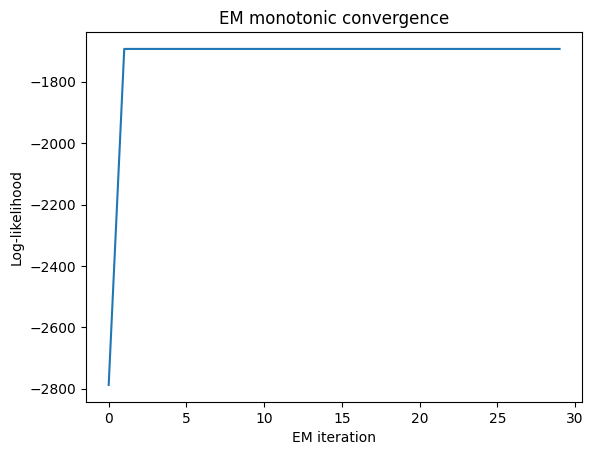

In [14]:
data_gmm = np.concatenate([rng.normal(20, 3, 300), rng.normal(60, 5, 200)])

mu = np.array([10.0, 70.0])
sigma = np.array([5.0, 5.0])
pi_weights = np.array([0.5, 0.5])

log_likelihood_history = []
for iteration in range(30):
    resp = np.array([pi_weights[k]*stats.norm(mu[k], sigma[k]).pdf(data_gmm) for k in range(2)])
    total_lik = resp.sum(axis=0)
    log_likelihood_history.append(np.log(total_lik).sum())
    resp = resp / total_lik

    Nk = resp.sum(axis=1)
    mu = (resp @ data_gmm) / Nk
    sigma = np.sqrt((resp * (data_gmm - mu[:,None])**2).sum(axis=1) / Nk)
    pi_weights = Nk / len(data_gmm)

print(f"Converged means: {np.round(mu,2)}  (true means were 20 and 60)")
print(f"Converged mixing weights: {np.round(pi_weights,2)}  (true weights were 0.6 and 0.4)")

diffs = np.diff(log_likelihood_history)
print(f"\nLog-likelihood never decreased across iterations: {(diffs >= -1e-8).all()}")
plt.plot(log_likelihood_history); plt.xlabel("EM iteration"); plt.ylabel("Log-likelihood"); plt.title("EM monotonic convergence")

## 13. GMM Customer Segmentation with scikit-learn (Section 81, Project 6)

In [15]:
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

n = 3000
z = rng.choice([0,1,2], size=n, p=[0.5,0.35,0.15])
spending = rng.normal(np.array([30,90,250])[z], np.array([10,25,60])[z])
frequency = rng.normal(np.array([2,5,12])[z], np.array([1,2,3])[z])
X = np.column_stack([spending, frequency])
X_scaled = StandardScaler().fit_transform(X)

gmm = GaussianMixture(n_components=3, random_state=24, n_init=5).fit(X_scaled)
soft_assignments = gmm.predict_proba(X_scaled)

max_prob = soft_assignments.max(axis=1)
ambiguous_pct = (max_prob < 0.6).mean()
print(f"Soft assignment for one customer: {np.round(soft_assignments[0], 3)}")
print(f"% of customers with ambiguous segment membership: {ambiguous_pct:.1%}")

Soft assignment for one customer: [0.982 0.018 0.   ]
% of customers with ambiguous segment membership: 0.4%


## 14. Mahalanobis Distance Anomaly Detection (Sections 51, 95, 128)

In [16]:
normal_data = rng.multivariate_normal(mean=[50, 100], cov=[[25, 15],[15, 64]], size=2000)
mu_hat = normal_data.mean(axis=0)
Sigma_hat = np.cov(normal_data, rowvar=False)
Sigma_inv = np.linalg.inv(Sigma_hat)

def mahalanobis_distance(x, mu, Sigma_inv):
    diff = x - mu
    return np.sqrt(diff @ Sigma_inv @ diff)

test_points = np.array([[51, 102], [80, 40]])
for p in test_points:
    d = mahalanobis_distance(p, mu_hat, Sigma_inv)
    euclid = np.linalg.norm(p - mu_hat)
    print(f"Point {p}: Mahalanobis={d:.2f}, Euclidean={euclid:.2f}  {'-> ANOMALY' if d > 3 else '-> normal'}")

Point [ 51 102]: Mahalanobis=0.27, Euclidean=2.20  -> normal
Point [80 40]: Mahalanobis=12.01, Euclidean=67.16  -> ANOMALY


## 15. Calibration: Reliability Curve and Brier Score (Section 70)

Brier score: 0.0281


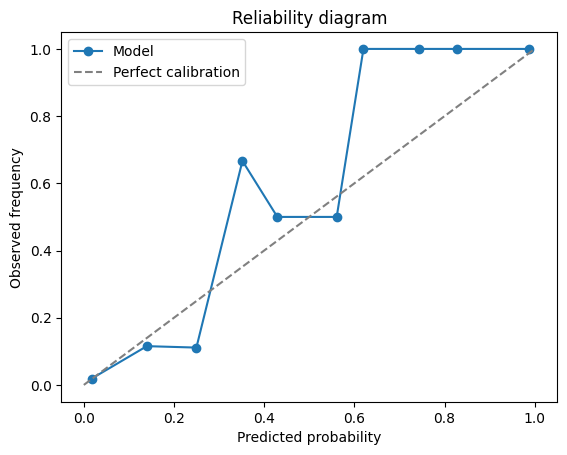

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import brier_score_loss

X, y = make_classification(n_samples=2000, weights=[0.9, 0.1], random_state=20)
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=20)

model = LogisticRegression().fit(X_train, y_train)
probs = model.predict_proba(X_test)[:, 1]

fraction_positive, mean_predicted = calibration_curve(y_test, probs, n_bins=10)
print(f"Brier score: {brier_score_loss(y_test, probs):.4f}")

plt.plot(mean_predicted, fraction_positive, marker='o', label='Model')
plt.plot([0,1],[0,1], linestyle='--', color='gray', label='Perfect calibration')
plt.xlabel("Predicted probability"); plt.ylabel("Observed frequency"); plt.legend()
plt.title("Reliability diagram")

## 16. Cost-Based Decision Thresholds and Expected Loss (Sections 122-123)

In [18]:
def optimal_threshold(cost_fp, cost_fn):
    return cost_fp / (cost_fp + cost_fn)

print(f"Fraud threshold (C_FP=20, C_FN=500): {optimal_threshold(20, 500):.4f}")
print(f"Healthcare screening threshold (C_FP=150, C_FN=8000): {optimal_threshold(150, 8000):.4f}")
print(f"Symmetric-cost threshold: {optimal_threshold(100, 100):.4f}")

# Three-action expected-cost decision (Section 123)
p_fraud = 0.15
costs = {
    "approve": p_fraud * 500 + (1-p_fraud) * 0,
    "decline": p_fraud * 0 + (1-p_fraud) * 30,
    "manual_review": 8,
}
best_action = min(costs, key=costs.get)
print("Expected cost per action:", {k: round(v,2) for k,v in costs.items()})
print(f"Optimal action: {best_action}")

Fraud threshold (C_FP=20, C_FN=500): 0.0385
Healthcare screening threshold (C_FP=150, C_FN=8000): 0.0184
Symmetric-cost threshold: 0.5000
Expected cost per action: {'approve': 75.0, 'decline': 25.5, 'manual_review': 8}
Optimal action: manual_review


## 17. Classic Interview Traps: Monty Hall and the Birthday Problem (Section 134)

In [19]:
# Monty Hall
n_sim = 200000
prize_door = rng.integers(0, 3, n_sim)
my_pick = rng.integers(0, 3, n_sim)
switch_wins = (prize_door != my_pick)
print(f"Monty Hall - switch win rate: {switch_wins.mean():.4f}  (theory: 0.6667)")

# Birthday Problem
def birthday_collision_prob_theory(n_people):
    p_no_collision = 1.0
    for i in range(n_people):
        p_no_collision *= (365 - i) / 365
    return 1 - p_no_collision

def birthday_collision_prob_simulated(n_people, n_trials=100000):
    collisions = 0
    for _ in range(n_trials):
        birthdays = rng.integers(0, 365, n_people)
        if len(np.unique(birthdays)) < n_people:
            collisions += 1
    return collisions / n_trials

theory = birthday_collision_prob_theory(23)
simulated = birthday_collision_prob_simulated(23, n_trials=20000)
print(f"\nBirthday Problem (23 people) - theoretical: {theory:.4f}, simulated: {simulated:.4f}")

Monty Hall - switch win rate: 0.6652  (theory: 0.6667)

Birthday Problem (23 people) - theoretical: 0.5073, simulated: 0.5095


## 18. Markov Chain: Customer Lifecycle Simulation (Section 78)

In [20]:
states = ["New", "Active", "At-Risk", "Churned"]
T = np.array([
    [0.10, 0.80, 0.10, 0.00],
    [0.00, 0.85, 0.10, 0.05],
    [0.00, 0.30, 0.50, 0.20],
    [0.00, 0.00, 0.00, 1.00],
])

state = 0
journey = [states[state]]
for _ in range(10):
    state = rng.choice(4, p=T[state])
    journey.append(states[state])
print("Simulated customer journey:", " -> ".join(journey))

dist = np.array([1, 0, 0, 0])
for _ in range(200):
    dist = dist @ T
print(f"\nLong-run state distribution: {dict(zip(states, np.round(dist,3)))}")

Simulated customer journey: New -> Active -> Active -> Active -> Active -> Active -> At-Risk -> Churned -> Churned -> Churned -> Churned

Long-run state distribution: {'New': np.float64(0.0), 'Active': np.float64(0.0), 'At-Risk': np.float64(0.0), 'Churned': np.float64(1.0)}


## 19. Bootstrap Uncertainty Estimation (Section 88)

In [21]:
original_data = rng.exponential(scale=50, size=200)
observed_median = np.median(original_data)

B = 5000
bootstrap_medians = np.array([np.median(rng.choice(original_data, size=len(original_data), replace=True)) for _ in range(B)])

print(f"Observed median: {observed_median:.2f}")
print(f"Bootstrap standard error: {bootstrap_medians.std():.2f}")
print(f"Bootstrap 95% interval: {np.percentile(bootstrap_medians, [2.5, 97.5])}")

Observed median: 39.24
Bootstrap standard error: 3.19
Bootstrap 95% interval: [32.4677039  46.11999605]


## 20. Summary

This workbook executed real, verified computations for the core techniques of the Probability for Machine Learning module: probability rules, Bayes' theorem, the base-rate/diagnostic-testing problem, the full distribution catalog, LLN/CLT, Monte Carlo estimation, Bayesian updating and A/B testing, MLE, Naive Bayes (manual and scikit-learn), numerically stable softmax/log-sum-exp, EM for Gaussian mixtures, GMM segmentation, Mahalanobis anomaly detection, model calibration, cost-based decision thresholds, the Monty Hall and Birthday interview traps, Markov chains, and bootstrap uncertainty.

Every result above is computed directly - not illustrative pseudocode - so each can be re-run, perturbed, and inspected to build genuine intuition for how these techniques behave on real (simulated) data.

**Kajola Gbenga**
*Data Scientist & AI Engineer*